In [ ]:
import pandas as pd
import os
import kagglehub

# Download latest version
path = kagglehub.dataset_download("dhruvildave/en-fr-translation-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'en-fr-translation-dataset' dataset.
Path to dataset files: /kaggle/input/en-fr-translation-dataset


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("devicharith/language-translation-englishfrench")

print("Path to dataset files:", path)

100%|██████████| 3.51M/3.51M [00:00<00:00, 58.6MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/devicharith/language-translation-englishfrench/versions/2


In [ ]:
import os

for root, dirs, files in os.walk(path):
    for file in files:
        l = os.path.join(root, file)


In [ ]:

import pandas as pd
file_path = os.path.join(path, l)
df = pd.read_csv(file_path)
df.head()
'''
df = df.sample(
    n=20000,
    random_state=42
).reset_index(drop=True)
'''

'\ndf = df.sample(\n    n=20000,\n    random_state=42\n).reset_index(drop=True)\n'

In [ ]:
print(df.isnull().sum())

English words/sentences    0
French words/sentences     0
dtype: int64


In [ ]:
import re
def tokenize(sent):
  sent = sent.lower()
  sent = re.sub(r"([.,!?;:])", r" \1", sent)
  return sent.split()

In [ ]:
t  = df["English words/sentences"][0]

In [ ]:
tokenize(t)

['hi', '.']

In [ ]:
from collections import Counter
#Counter(df["English words/sentences"])

class Vocab:
  def __init__(self):
    self.word2idx = {
        "<PAD>" : 0,
        "<UNK>" : 1,
        "<SOS>" : 2,
        "<EOS>" : 3
    }

    self.idx2word = {
        0 : "<PAD>",
        1 : "<UNK>",
        2 : "<SOS>",
        3: "<EOS>",

    }
  def build(self, sents, min_freq = 1):
    counter = Counter()
    for sent in sents.tolist():
      t = tokenize(sent)
      counter.update(t)

    for word, freq in counter.items():
      if freq >= min_freq:
        idx = len(self.word2idx)
        self.word2idx[word] = idx
        self.idx2word[idx] = word

    def numericalize(self, sent):
      tokens = tokenize(sent)
      return [self.word2idx.get(token, self.word2idx["<UNK>"]) for token in tokens]

    def __len__(self):
      return len(self.word2idx)

In [ ]:
df

,English words/sentences,French words/sentences
0,Hi.,Salut!
1,Run!,Cours !
2,Run!,Courez !
3,Who?,Qui ?
4,Wow!,Ça alors !
...,...,...
175616,"Top-down economics never works, said Obama. ""T...","« L'économie en partant du haut vers le bas, ç..."
175617,A carbon footprint is the amount of carbon dio...,Une empreinte carbone est la somme de pollutio...
175618,Death is something that we're often discourage...,La mort est une chose qu'on nous décourage sou...
175619,Since there are usually multiple websites on a...,Puisqu'il y a de multiples sites web sur chaqu...


In [ ]:
eng_vocab = Vocab()
fre_vocab = Vocab()

eng_vocab.build(df["English words/sentences"])
fre_vocab.build(df["French words/sentences"])

In [ ]:
print("\nEnglish:")
print(list(eng_vocab.word2idx.items())[:20])

print("\nFrench:")
print(list(fre_vocab.word2idx.items())[:20])


English:
[('<PAD>', 0), ('<UNK>', 1), ('<SOS>', 2), ('<EOS>', 3), ('hi', 4), ('.', 5), ('run', 6), ('!', 7), ('who', 8), ('?', 9), ('wow', 10), ('fire', 11), ('help', 12), ('jump', 13), ('stop', 14), ('wait', 15), ('go', 16), ('on', 17), ('hello', 18), ('i', 19)]

French:
[('<PAD>', 0), ('<UNK>', 1), ('<SOS>', 2), ('<EOS>', 3), ('salut', 4), ('!', 5), ('cours', 6), ('courez', 7), ('qui', 8), ('?', 9), ('ça', 10), ('alors', 11), ('au', 12), ('feu', 13), ('à', 14), ("l'aide", 15), ('saute', 16), ('.', 17), ('suffit', 18), ('stop', 19)]


In [ ]:
from collections import Counter
#Counter(df["English words/sentences"])

class Vocab:
  def __init__(self):
    self.word2idx = {
        "<PAD>" : 0,
        "<UNK>" : 1,
        "<SOS>" : 2,
        "<EOS>" : 3
    }

    self.idx2word = {
        0 : "<PAD>",
        1 : "<UNK>",
        2 : "<SOS>",
        3: "<EOS>",

    }
  def build(self, sents, min_freq = 1):
    counter = Counter()
    for sent in sents.tolist():
      t = tokenize(sent)
      counter.update(t)

    for word, freq in counter.items():
      if freq >= min_freq:
        idx = len(self.word2idx)
        self.word2idx[word] = idx
        self.idx2word[idx] = word

  def numericalize(self, sent):
      tokens = tokenize(sent)
      return ( [self.word2idx["<SOS>"]] + [self.word2idx.get(token, self.word2idx["<UNK>"]) for token in tokens] + [self.word2idx["<EOS>"]])
  def __len__(self):
      return len(self.word2idx)

In [ ]:
english_vocab = Vocab()
french_vocab = Vocab()

english_vocab.build(df["English words/sentences"])
french_vocab.build(df["French words/sentences"])

print("\nEnglish:")
print(list(english_vocab.word2idx.items())[:20])

print("\nFrench:")
print(list(french_vocab.word2idx.items())[:20])


English:
[('<PAD>', 0), ('<UNK>', 1), ('<SOS>', 2), ('<EOS>', 3), ('hi', 4), ('.', 5), ('run', 6), ('!', 7), ('who', 8), ('?', 9), ('wow', 10), ('fire', 11), ('help', 12), ('jump', 13), ('stop', 14), ('wait', 15), ('go', 16), ('on', 17), ('hello', 18), ('i', 19)]

French:
[('<PAD>', 0), ('<UNK>', 1), ('<SOS>', 2), ('<EOS>', 3), ('salut', 4), ('!', 5), ('cours', 6), ('courez', 7), ('qui', 8), ('?', 9), ('ça', 10), ('alors', 11), ('au', 12), ('feu', 13), ('à', 14), ("l'aide", 15), ('saute', 16), ('.', 17), ('suffit', 18), ('stop', 19)]


In [ ]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(df, test_size= 0.2, random_state = 42)



In [ ]:
df["English words/sentences"]
df["French words/sentences"]

,French words/sentences
0,Salut!
1,Cours !
2,Courez !
3,Qui ?
4,Ça alors !
...,...
175616,"« L'économie en partant du haut vers le bas, ç..."
175617,Une empreinte carbone est la somme de pollutio...
175618,La mort est une chose qu'on nous décourage sou...
175619,Puisqu'il y a de multiples sites web sur chaqu...


In [ ]:
import torch
from torch.utils.data import Dataset


class TranslateDataset(Dataset):
  def __init__(self, df, english_vocab, french_vocab):
    self.data = df.reset_index(drop = True)

    self.eng = english_vocab
    self.fre = french_vocab

  def __len__(self):
    return len(self.data)

  def __getitem__(self, index):
    en = self.data.iloc[index]["English words/sentences"]
    fr = self.data.iloc[index]["French words/sentences"]

    engl_ids = self.eng.numericalize(en)
    fren_ids = self.fre.numericalize(fr)

    return (
        torch.tensor(engl_ids, dtype = torch.long),
        torch.tensor(fren_ids, dtype = torch.long)
    )


In [ ]:
train_data = TranslateDataset(
    train_df, english_vocab, french_vocab
)

In [ ]:
train_dataset = TranslateDataset(
    train_df,
    english_vocab,
    french_vocab
)

val_dataset = TranslateDataset(
    val_df,
    english_vocab,
    french_vocab
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))

Training dataset: 140496
Validation dataset: 35125


In [ ]:
src, trg = train_dataset[0]

print("Source:", src)
print("Target:", trg)

Source: tensor([   2,  234,  101,   37,  137,  540, 1666, 4281,   35,    9,    3])
Target: tensor([    2,  1322,   537,   613,  3470,   182, 23482,     9,     3])


In [ ]:
from torch.nn.utils.rnn import pad_sequence

def padding(batch):
  input = []
  label = []

  for i, l in batch:
    input.append(i)
    label.append(l)

  input = pad_sequence( input, batch_first= True, padding_value= english_vocab.word2idx["<PAD>"])
  label = pad_sequence( label, batch_first= True, padding_value= french_vocab.word2idx["<PAD>"])

  return input, label

In [ ]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn= padding
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn= padding
)

In [ ]:
src, trg = next(iter(train_loader))

print("Source shape:", src.shape)
print("Target shape:", trg.shape)

print("\nSource batch:")
print(src)

print("\nTarget batch:")
print(trg)

Source shape: torch.Size([32, 16])
Target shape: torch.Size([32, 16])

Source batch:
tensor([[    2,   635,  6086,   358,  9813,   253,  4767,    33,   188,  5565,
             5,     3,     0,     0,     0,     0],
        [    2,  9796,   248,  1147,  2000,    97,   187,   253,   116,  8196,
             5,     3,     0,     0,     0,     0],
        [    2,   461,  1265,   290,  2394,     5,     3,     0,     0,     0,
             0,     0,     0,     0,     0,     0],
        [    2,   237,    95,    35,  1672,   203,   275,   125,     5,     3,
             0,     0,     0,     0,     0,     0],
        [    2,    19,   871,    31,   251,   101,  2133,    62,     5,     3,
             0,     0,     0,     0,     0,     0],
        [    2,  1674,    30,   116,  2749,   351,   248,   550,     5,     3,
             0,     0,     0,     0,     0,     0],
        [    2,   217,    33,    57,   358,   116,   140,     5,     3,     0,
             0,     0,     0,     0,     0,     0]

In [ ]:
import torch.nn as nn

class Encoder(nn.Module):
  def __init__(self,input_dim,  embedding_dim, hidden_dim,num_layer = 1, dropout = 0.0 ):
    super().__init__()

    self.embedding = nn.Embedding(input_dim, embedding_dim, padding_idx= english_vocab.word2idx["<PAD>"])
    self.rnn = nn.GRU(embedding_dim, hidden_dim, num_layers = num_layer, dropout= dropout if num_layer > 1 else 0)
    self.dropout = nn.Dropout(dropout)

  def forward(self, src):
    x = self.dropout(self.embedding(src))
    x = x.permute(1, 0, 2)

    op, hid = self.rnn(x)

    return hid

In [ ]:
INPUT_DIM = len(english_vocab)
OUTPUT_DIM = len(french_vocab)

ENC_EMB_DIM = 256
HID_DIM = 512

encoder = Encoder(
    input_dim=INPUT_DIM,
    embedding_dim=ENC_EMB_DIM,
    hidden_dim=HID_DIM
)

print(encoder)

In [ ]:
src, trg = next(iter(train_loader))

print("Source shape:", src.shape)

In [ ]:
hidden = encoder(src)

print("Hidden shape:", hidden.shape)

In [ ]:
hidden

In [ ]:
class Decoder(nn.Module):
  def __init__(self, output_dim, embedding_dim, hidden_dim, num_layers = 1, dropout = 0.0):
    super().__init__()
    self.output_dim = output_dim
    self.embedding = nn.Embedding(output_dim, embedding_dim, padding_idx= french_vocab.word2idx["<PAD>"])
    self.rnn = nn.GRU(
        embedding_dim, hidden_dim, num_layers, dropout= dropout if num_layers > 1 else 0
    )

    self.fc = nn.Linear(hidden_dim, output_dim)

    self.dropout = nn.Dropout(dropout)


  def forward(self, input, hidden):
    input = input.unsqueeze(0)
    embedded = self.dropout(self.embedding(input))
    op, hidden = self.rnn(embedded, hidden)
    prediction = self.fc(op.squeeze(0))

    return prediction, hidden

In [ ]:
DEC_EMB_DIM = 256

decoder = Decoder(
    output_dim=OUTPUT_DIM,
    embedding_dim=DEC_EMB_DIM,
    hidden_dim=HID_DIM
)

print(decoder)

In [ ]:
src, trg = next(iter(train_loader))

hidden = encoder(src)

print("Hidden:", hidden)

In [ ]:
src

In [ ]:
input_token = trg[:, 0]
input_token.shape

In [ ]:
prediction, hidden = decoder( input_token, hidden)

In [ ]:
prediction

In [ ]:
class SeqtoSeq(nn.Module):
  def __init__(
        self,
        encoder,
        decoder,
        device
    ):

        super().__init__()

        self.encoder = encoder
        self.decoder = decoder
        self.device = device
  def forward(self, src, trg, teacher_forcing_ratio=0.5) :
    batch_size = src.shape[0]
    trg_len = trg.shape[1]
    trg_vocab_size = self.decoder.output_dim
    outputs = torch.zeros(batch_size, trg_len, trg_vocab_size).to(self.device)
    hidden = self.encoder(src)
    input = trg[:, 0] #1st decoder input
    for t in range(1, trg_len):
      output, hidden = self.decoder(input, hidden)
      outputs[:, t, :] = output
      top1 = output.argmax(1)
      teacher_force = (
                torch.rand(1).item() < teacher_forcing_ratio
            )
      if teacher_force:
                input = trg[:, t]
      else:
                input = top1

    return outputs



In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

In [ ]:
model = SeqtoSeq( encoder, decoder, device).to(device)
print(model)

In [ ]:
import torch.optim as optim

PAD_IDX = french_vocab.word2idx["<PAD>"]
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
optimizer = optim.Adam( model.parameters(), lr=0.001)

In [ ]:
def train(model, iterator, optimizer, criterion, clip=1):

    model.train()

    epoch_loss = 0

    for src, trg in iterator:

        src = src.to(device)
        trg = trg.to(device)

        optimizer.zero_grad()

        output = model(
            src,
            trg,
            teacher_forcing_ratio=0.5
        )

        output_dim = output.shape[-1]
        output = output[:, 1:, :].contiguous().view(
            -1,
            output_dim
        )

        trg = trg[:, 1:].contiguous().view(-1)

        loss = criterion(
            output,
            trg
        )

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            clip
        )

        optimizer.step()
        epoch_loss += loss.item()

    return epoch_loss / len(iterator)

In [ ]:
def evaluate(model, iterator, criterion):

    model.eval()

    epoch_loss = 0

    with torch.no_grad():

        for src, trg in iterator:

            src = src.to(device)
            trg = trg.to(device)

            output = model(
                src,
                trg,
                teacher_forcing_ratio=0
            )

            output_dim = output.shape[-1]

            output = output[:, 1:, :].contiguous().view(
                -1,
                output_dim
            )

            trg = trg[:, 1:].contiguous().view(-1)

            loss = criterion(
                output,
                trg
            )

            epoch_loss += loss.item()

    return epoch_loss / len(iterator)

In [ ]:
import math
import time

N_EPOCHS = 5

best_valid_loss = float("inf")

for epoch in range(N_EPOCHS):

    start_time = time.time()

    train_loss = train(
        model,
        train_loader,
        optimizer,
        criterion
    )

    valid_loss = evaluate(
        model,
        val_loader,
        criterion
    )

    end_time = time.time()

    epoch_mins = int((end_time - start_time) // 60)
    epoch_secs = int((end_time - start_time) % 60)

    if valid_loss < best_valid_loss:

        best_valid_loss = valid_loss

        torch.save(
            model.state_dict(),
            "translation_model.pt"
        )

    print(
        f"Epoch: {epoch+1:02} | "
        f"Time: {epoch_mins}m {epoch_secs}s"
    )

    print(
        f"\tTrain Loss: {train_loss:.3f}"
    )

    print(
        f"\tVal. Loss: {valid_loss:.3f}"
    )

KeyboardInterrupt: 

In [ ]:
model.load_state_dict(
    torch.load(
        "translation_model2.pt",
        map_location=device
    )
)

<All keys matched successfully>

In [ ]:
def translate_sentence(
    sentence,
    model,
    english_vocab,
    french_vocab,
    device,
    max_len=50
):

    model.eval()

    tokens = tokenize(sentence)

    tokens = [
        "<SOS>"
    ] + tokens + [
        "<EOS>"
    ]

    src_indexes = [
        english_vocab.word2idx.get(
            token,
            english_vocab.word2idx["<UNK>"]
        )
        for token in tokens
    ]

    src_tensor = torch.tensor(
        src_indexes,
        dtype=torch.long
    ).unsqueeze(0).to(device)

    with torch.no_grad():

        hidden = model.encoder(
            src_tensor
        )

    input_token = torch.tensor(
        [french_vocab.word2idx["<SOS>"]],
        dtype=torch.long
    ).to(device)

    translated_tokens = []

    for _ in range(max_len):

        with torch.no_grad():

            output, hidden = model.decoder(
                input_token,
                hidden
            )

        predicted_token = output.argmax(1).item()

        if predicted_token == french_vocab.word2idx["<EOS>"]:
            break

        translated_tokens.append(
            french_vocab.idx2word[predicted_token]
        )

        input_token = torch.tensor(
            [predicted_token],
            dtype=torch.long
        ).to(device)

    return translated_tokens

In [ ]:
english = "I think i hate myself" #val_df.iloc[0]["English words/sentences"]
actual_french = "Je pense que je me déteste" #val_df.iloc[0]["French words/sentences"]

prediction = translate_sentence(
    english,
    model,
    english_vocab,
    french_vocab,
    device
)

print("English:")
print(english)

print("\nActual French:")
print(actual_french)

print("\nPredicted French:")
print(" ".join(prediction))

English:
I think i hate myself

Actual French:
Je pense que je me déteste

Predicted French:
je pense que je me suis seul .


In [ ]:
import math
import time
loss_vanilla_train = []
loss_vanilla_val = []
N_EPOCHS = 10

best_valid_loss = float("inf")

for epoch in range(N_EPOCHS):

    start_time = time.time()

    train_loss = train(
        model,
        train_loader,
        optimizer,
        criterion
    )

    valid_loss = evaluate(
        model,
        val_loader,
        criterion
    )

    loss_vanilla_train.append(train_loss)
    loss_vanilla_val.append(valid_loss)

    end_time = time.time()

    epoch_mins = int((end_time - start_time) // 60)
    epoch_secs = int((end_time - start_time) % 60)

    if valid_loss < best_valid_loss:

        best_valid_loss = valid_loss

        torch.save(
            model.state_dict(),
            "translation_model2.pt"
        )

    print(
        f"Epoch: {epoch+1:02} | "
        f"Time: {epoch_mins}m {epoch_secs}s"
    )

    print(
        f"\tTrain Loss: {train_loss:.3f}"
    )

    print(
        f"\tVal. Loss: {valid_loss:.3f}"
    )

Epoch: 01 | Time: 10m 41s
	Train Loss: 1.657
	Val. Loss: 3.046
Epoch: 02 | Time: 10m 17s
	Train Loss: 1.436
	Val. Loss: 3.030
Epoch: 03 | Time: 10m 13s
	Train Loss: 1.318
	Val. Loss: 3.116
Epoch: 04 | Time: 10m 15s
	Train Loss: 1.259
	Val. Loss: 3.168
Epoch: 05 | Time: 10m 12s
	Train Loss: 1.210
	Val. Loss: 3.220
Epoch: 06 | Time: 10m 15s
	Train Loss: 1.174
	Val. Loss: 3.285
Epoch: 07 | Time: 10m 21s
	Train Loss: 1.150
	Val. Loss: 3.325
Epoch: 08 | Time: 10m 17s
	Train Loss: 1.126
	Val. Loss: 3.329
Epoch: 09 | Time: 10m 15s
	Train Loss: 1.115
	Val. Loss: 3.371
Epoch: 10 | Time: 10m 12s
	Train Loss: 1.105
	Val. Loss: 3.414


In [ ]:
loss_vanilla_train

[1.657060566686384,
 1.4355248662394344,
 1.3184112170594506,
 1.258962609818953,
 1.2104512550610396,
 1.1741557738227688,
 1.150250682334535,
 1.1262623496545363,
 1.114614891153456,
 1.1046410833301537]

In [ ]:
loss_vanilla_val

[3.0464931741655414,
 3.030241714909211,
 3.1155570530500567,
 3.168424174650988,
 3.220247613276289,
 3.284549865132038,
 3.324858119144683,
 3.3294742070477734,
 3.37085532056395,
 3.414099891329072]

Attention


In [ ]:
import re
from collections import Counter

In [ ]:
import torch.nn as nn

class Encoder(nn.Module):
  def __init__(self,input_dim,  embedding_dim, hidden_dim,num_layer = 1, dropout = 0.0 ):
    super().__init__()

    self.embedding = nn.Embedding(input_dim, embedding_dim, padding_idx= english_vocab.word2idx["<PAD>"])
    self.rnn = nn.GRU(embedding_dim, hidden_dim, num_layers = num_layer, dropout= dropout if num_layer > 1 else 0)
    self.dropout = nn.Dropout(dropout)

  def forward(self, src):
    x = self.dropout(self.embedding(src))
    x = x.permute(1, 0, 2)

    op, hid = self.rnn(x)

    return hid

In [ ]:
INPUT_DIM = len(english_vocab)
OUTPUT_DIM = len(french_vocab)

ENC_EMB_DIM = 128
HID_DIM = 256

encoder = Encoder(
    input_dim=INPUT_DIM,
    embedding_dim=ENC_EMB_DIM,
    hidden_dim=HID_DIM
)

print(encoder)

Encoder(
  (embedding): Embedding(15004, 128, padding_idx=0)
  (rnn): GRU(128, 256)
  (dropout): Dropout(p=0.0, inplace=False)
)


In [ ]:
src, trg = next(iter(train_loader))

print("Source shape:", src.shape)

Source shape: torch.Size([32, 17])


In [ ]:
hidden = encoder(src)

print("Hidden shape:", hidden.shape)

Hidden shape: torch.Size([1, 32, 256])


In [ ]:
hidden

tensor([[[ 0.0123,  0.0173, -0.0674,  ..., -0.0109,  0.0632,  0.0489],
         [ 0.0143,  0.0158, -0.0657,  ..., -0.0100,  0.0630,  0.0458],
         [ 0.0131,  0.0154, -0.0675,  ..., -0.0099,  0.0629,  0.0469],
         ...,
         [ 0.0119,  0.0164, -0.0689,  ..., -0.0119,  0.0635,  0.0483],
         [-0.0045,  0.0194, -0.0681,  ..., -0.0195,  0.0709,  0.0408],
         [ 0.0133,  0.0153, -0.0670,  ..., -0.0104,  0.0628,  0.0449]]],
       grad_fn=<StackBackward0>)

In [ ]:
class Decoder(nn.Module):
  def __init__(self, output_dim, embedding_dim, hidden_dim, num_layers = 1, dropout = 0.0):
    super().__init__()
    self.output_dim = output_dim
    self.embedding = nn.Embedding(output_dim, embedding_dim, padding_idx= french_vocab.word2idx["<PAD>"])
    self.rnn = nn.GRU(
        embedding_dim, hidden_dim, num_layers, dropout= dropout if num_layers > 1 else 0
    )

    self.fc = nn.Linear(hidden_dim, output_dim)

    self.dropout = nn.Dropout(dropout)


  def forward(self, input, hidden):
    input = input.unsqueeze(0)
    embedded = self.dropout(self.embedding(input))
    op, hidden = self.rnn(embedded, hidden)
    prediction = self.fc(op.squeeze(0))

    return prediction, hidden

In [ ]:
DEC_EMB_DIM = 128

decoder = Decoder(
    output_dim=OUTPUT_DIM,
    embedding_dim=DEC_EMB_DIM,
    hidden_dim=HID_DIM
)

print(decoder)

Decoder(
  (embedding): Embedding(29720, 128, padding_idx=0)
  (rnn): GRU(128, 256)
  (fc): Linear(in_features=256, out_features=29720, bias=True)
  (dropout): Dropout(p=0.0, inplace=False)
)


In [ ]:
src, trg = next(iter(train_loader))

hidden = encoder(src)

print("Hidden:", hidden)

Hidden: tensor([[[ 0.0120,  0.0160, -0.0665,  ..., -0.0110,  0.0648,  0.0476],
         [ 0.0145,  0.0136, -0.0669,  ..., -0.0101,  0.0628,  0.0472],
         [ 0.0110,  0.0172, -0.0672,  ..., -0.0089,  0.0652,  0.0479],
         ...,
         [ 0.0145,  0.0133, -0.0671,  ..., -0.0096,  0.0633,  0.0465],
         [ 0.0119,  0.0168, -0.0685,  ..., -0.0093,  0.0655,  0.0441],
         [ 0.0132,  0.0143, -0.0680,  ..., -0.0098,  0.0631,  0.0469]]],
       grad_fn=<StackBackward0>)


In [ ]:
src

tensor([[   2,   49, 6769,  635, 6423, 6424,    5,    3,    0,    0,    0,    0,
            0,    0,    0,    0,    0],
        [   2,   93,  399,  327,    5,    3,    0,    0,    0,    0,    0,    0,
            0,    0,    0,    0,    0],
        [   2,  635,  575,  673,  116, 1995,  623,    5,    3,    0,    0,    0,
            0,    0,    0,    0,    0],
        [   2,   51, 1752,  594,  275,  751,    5,    3,    0,    0,    0,    0,
            0,    0,    0,    0,    0],
        [   2, 6779,   97, 1883, 1240,  915,  125,  218,   61,    5,    3,    0,
            0,    0,    0,    0,    0],
        [   2,   49,  155,  554, 1147, 6607,    5,    3,    0,    0,    0,    0,
            0,    0,    0,    0,    0],
        [   2,   19, 6377, 1729,    5,    3,    0,    0,    0,    0,    0,    0,
            0,    0,    0,    0,    0],
        [   2,   19,   47,  112, 1109,  160,    5,    3,    0,    0,    0,    0,
            0,    0,    0,    0,    0],
        [   2,   19,  549,  289,

In [ ]:
input_token = trg[:, 0]
input_token.shape

torch.Size([32])

In [ ]:
prediction, hidden = decoder( input_token, hidden)

In [ ]:
prediction

tensor([[-0.0807,  0.1249,  0.0397,  ..., -0.1753, -0.1426,  0.2130],
        [-0.0815,  0.1245,  0.0397,  ..., -0.1754, -0.1436,  0.2127],
        [-0.0803,  0.1257,  0.0406,  ..., -0.1755, -0.1422,  0.2132],
        ...,
        [-0.0816,  0.1246,  0.0396,  ..., -0.1753, -0.1438,  0.2127],
        [-0.0801,  0.1255,  0.0406,  ..., -0.1740, -0.1426,  0.2140],
        [-0.0812,  0.1246,  0.0397,  ..., -0.1755, -0.1436,  0.2127]],
       grad_fn=<AddmmBackward0>)

In [ ]:
class SeqtoSeq(nn.Module):
  def __init__(
        self,
        encoder,
        decoder,
        device
    ):

        super().__init__()

        self.encoder = encoder
        self.decoder = decoder
        self.device = device
  def forward(self, src, trg, teacher_forcing_ratio=0.5) :
    batch_size = src.shape[0]
    trg_len = trg.shape[1]
    trg_vocab_size = self.decoder.output_dim
    outputs = torch.zeros(batch_size, trg_len, trg_vocab_size).to(self.device)
    hidden = self.encoder(src)
    input = trg[:, 0] #1st decoder input
    for t in range(1, trg_len):
      output, hidden = self.decoder(input, hidden)
      outputs[:, t, :] = output
      top1 = output.argmax(1)
      teacher_force = (
                torch.rand(1).item() < teacher_forcing_ratio
            )
      if teacher_force:
                input = trg[:, t]
      else:
                input = top1

    return outputs



In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [ ]:
model = SeqtoSeq( encoder, decoder, device).to(device)
print(model)

SeqtoSeq(
  (encoder): Encoder(
    (embedding): Embedding(15004, 128, padding_idx=0)
    (rnn): GRU(128, 256)
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (decoder): Decoder(
    (embedding): Embedding(29720, 128, padding_idx=0)
    (rnn): GRU(128, 256)
    (fc): Linear(in_features=256, out_features=29720, bias=True)
    (dropout): Dropout(p=0.0, inplace=False)
  )
)


In [ ]:
import torch.optim as optim

PAD_IDX = french_vocab.word2idx["<PAD>"]
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
optimizer = optim.Adam( model.parameters(), lr=0.001)

In [ ]:
def train(model, iterator, optimizer, criterion, clip=1):

    model.train()

    epoch_loss = 0

    for src, trg in iterator:

        src = src.to(device)
        trg = trg.to(device)

        optimizer.zero_grad()

        output = model(
            src,
            trg,
            teacher_forcing_ratio=0.5
        )

        output_dim = output.shape[-1]
        output = output[:, 1:, :].contiguous().view(
            -1,
            output_dim
        )

        trg = trg[:, 1:].contiguous().view(-1)

        loss = criterion(
            output,
            trg
        )

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            clip
        )

        optimizer.step()
        epoch_loss += loss.item()

    return epoch_loss / len(iterator)

In [ ]:
def evaluate(model, iterator, criterion):

    model.eval()

    epoch_loss = 0

    with torch.no_grad():

        for src, trg in iterator:

            src = src.to(device)
            trg = trg.to(device)

            output = model(
                src,
                trg,
                teacher_forcing_ratio=0
            )

            output_dim = output.shape[-1]

            output = output[:, 1:, :].contiguous().view(
                -1,
                output_dim
            )

            trg = trg[:, 1:].contiguous().view(-1)

            loss = criterion(
                output,
                trg
            )

            epoch_loss += loss.item()

    return epoch_loss / len(iterator)

In [ ]:
import math
import time
loss_train_att = []
loss_val_att = []
N_EPOCHS = 10

best_valid_loss = float("inf")

for epoch in range(N_EPOCHS):

    start_time = time.time()

    train_loss = train(
        model,
        train_loader,
        optimizer,
        criterion
    )

    valid_loss = evaluate(
        model,
        val_loader,
        criterion
    )
    loss_train_att.append(train_loss)
    loss_val_att.append(val_loss)

    end_time = time.time()

    epoch_mins = int((end_time - start_time) // 60)
    epoch_secs = int((end_time - start_time) % 60)

    if valid_loss < best_valid_loss:

        best_valid_loss = valid_loss

        torch.save(
            model.state_dict(),
            "translation_model_attention.pt"
        )

    print(
        f"Epoch: {epoch+1:02} | "
        f"Time: {epoch_mins}m {epoch_secs}s"
    )

    print(
        f"\tTrain Loss: {train_loss:.3f}"
    )

    print(
        f"\tVal. Loss: {valid_loss:.3f}"
    )

KeyboardInterrupt: 

In [ ]:
model.load_state_dict(
    torch.load(
        "translation_model_attention.pt",
        map_location=device
    )
)

In [ ]:
def translate_sentence(
    sentence,
    model,
    english_vocab,
    french_vocab,
    device,
    max_len=50
):

    model.eval()

    tokens = tokenize(sentence)

    tokens = [
        "<SOS>"
    ] + tokens + [
        "<EOS>"
    ]

    src_indexes = [
        english_vocab.word2idx.get(
            token,
            english_vocab.word2idx["<UNK>"]
        )
        for token in tokens
    ]

    src_tensor = torch.tensor(
        src_indexes,
        dtype=torch.long
    ).unsqueeze(0).to(device)

    with torch.no_grad():

        hidden = model.encoder(
            src_tensor
        )

    input_token = torch.tensor(
        [french_vocab.word2idx["<SOS>"]],
        dtype=torch.long
    ).to(device)

    translated_tokens = []

    for _ in range(max_len):

        with torch.no_grad():

            output, hidden = model.decoder(
                input_token,
                hidden
            )

        predicted_token = output.argmax(1).item()

        if predicted_token == french_vocab.word2idx["<EOS>"]:
            break

        translated_tokens.append(
            french_vocab.idx2word[predicted_token]
        )

        input_token = torch.tensor(
            [predicted_token],
            dtype=torch.long
        ).to(device)

    return translated_tokens

In [ ]:
english = val_df.iloc[0]["English words/sentences"]
actual_french = val_df.iloc[0]["French words/sentences"]

prediction = translate_sentence(
    english,
    model,
    english_vocab,
    french_vocab,
    device
)

print("English:")
print(english)

print("\nActual French:")
print(actual_french)

print("\nPredicted French:")
print(" ".join(prediction))

In [ ]:
import torch.nn as nn

class Encoder(nn.Module):
  def __init__(self,input_dim,  embedding_dim, hidden_dim,num_layer = 1, dropout = 0.0 ):
    super().__init__()

    self.embedding = nn.Embedding(input_dim, embedding_dim, padding_idx= english_vocab.word2idx["<PAD>"])
    self.rnn = nn.GRU(embedding_dim, hidden_dim, num_layers = num_layer, dropout= dropout if num_layer > 1 else 0)
    self.dropout = nn.Dropout(dropout)

  def forward(self, src):
    x = self.dropout(self.embedding(src))
    x = x.permute(1, 0, 2)

    op, hid = self.rnn(x)

    return op, hid

In [ ]:
INPUT_DIM = len(english_vocab)
OUTPUT_DIM = len(french_vocab)

ENC_EMB_DIM = 256
HID_DIM = 512

encoder = Encoder(
    input_dim=INPUT_DIM,
    embedding_dim=ENC_EMB_DIM,
    hidden_dim=HID_DIM
)

print(encoder)

src, trg = next(iter(train_loader))

print("Source shape:", src.shape)

op, hidden = encoder(src)

print("Hidden shape:", hidden.shape)



Encoder(
  (embedding): Embedding(15004, 256, padding_idx=0)
  (rnn): GRU(256, 512)
  (dropout): Dropout(p=0.0, inplace=False)
)
Source shape: torch.Size([32, 15])
Hidden shape: torch.Size([1, 32, 512])


In [ ]:
ATTENTION_DIM = 128

In [ ]:
class Attention(nn.Module):

    def __init__(self, encoder_hidden_dim, decoder_hidden_dim, attention_dim):
        super().__init__()

        self.attn = nn.Linear( encoder_hidden_dim + decoder_hidden_dim, attention_dim)
        self.v = nn.Linear( attention_dim, 1, bias=False )

    def forward(self, hidden, encoder_outputs):
        hidden = hidden[-1]
        src_len = encoder_outputs.shape[0]
        hidden = hidden.unsqueeze(1)
        hidden = hidden.repeat(1, src_len, 1)
        encoder_outputs = encoder_outputs.permute(1, 0, 2)
        energy = torch.tanh( self.attn( torch.cat( (hidden, encoder_outputs), dim=2)))
        attention = self.v(energy).squeeze(2)
        return torch.softmax(attention, dim=1)

In [ ]:
class Decoder(nn.Module):
  def __init__(self, output_dim, embedding_dim, encoder_hidden_dim, decoder_hidden_dim, attention, num_layers = 1, dropout = 0.0):
    super().__init__()
    self.output_dim = output_dim
    self.embedding = nn.Embedding(output_dim, embedding_dim, padding_idx= french_vocab.word2idx["<PAD>"])
    self.attention = attention
    self.rnn = nn.GRU(
        embedding_dim + encoder_hidden_dim, decoder_hidden_dim, num_layers, dropout= dropout if num_layers > 1 else 0
    )

    self.fc = nn.Linear(embedding_dim
            + encoder_hidden_dim
            + decoder_hidden_dim, output_dim)

    self.dropout = nn.Dropout(dropout)


  def forward(self, input, hidden, encoder_outputs):
    input = input.unsqueeze(0)
    embedded = self.dropout(self.embedding(input))

    attention = self.attention(
        hidden,
        encoder_outputs
    )
    attention = attention.unsqueeze(1)
    encoder_outputs = encoder_outputs.permute(1, 0, 2)
    context = torch.bmm(
        attention,
        encoder_outputs
    )

    context = context.permute(
        1, 0, 2
    )
    """
    print("input:", input.shape)
    print("embedded:", embedded.shape)
    print("attention:", attention.shape)
    print("encoder_outputs:", encoder_outputs.shape)
    print("context:", context.shape)"""

    rnn_input = torch.cat(
        (embedded, context),
        dim=2
    )

    output, hidden = self.rnn(
        rnn_input,
        hidden
    )
    prediction = self.fc(
        torch.cat(
            (output, context, embedded),
            dim=2
        )
    )

    return prediction.squeeze(0), hidden

In [ ]:
DEC_EMB_DIM = 256



In [ ]:
src, trg = next(iter(train_loader))

encoder_outputs, hidden = encoder(src)

print("Hidden:", hidden)

Hidden: tensor([[[ 0.1712, -0.3153, -0.0923,  ..., -0.2880,  0.2406, -0.3157],
         [-0.0250, -0.0310, -0.0198,  ..., -0.0315, -0.0522,  0.0281],
         [-0.0274, -0.0302, -0.0139,  ..., -0.0309, -0.0553,  0.0281],
         ...,
         [-0.0258, -0.0297, -0.0126,  ..., -0.0303, -0.0569,  0.0287],
         [-0.0260, -0.0300, -0.0116,  ..., -0.0311, -0.0564,  0.0296],
         [-0.0232, -0.0322, -0.0379,  ..., -0.0220, -0.0485,  0.0229]]],
       grad_fn=<StackBackward0>)


In [ ]:
input_token = trg[:, 0]
input_token.shape

torch.Size([32])

In [ ]:
"""prediction, hidden = decoder( input_token, hidden,
    encoder_outputs)"""

'prediction, hidden = decoder( input_token, hidden,\n    encoder_outputs)'

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

INPUT_DIM = len(english_vocab)
OUTPUT_DIM = len(french_vocab)

ENC_EMB_DIM = 256
DEC_EMB_DIM = 256
HID_DIM = 512
ATTENTION_DIM = 128


# -------------------------
# 1. Encoder
# -------------------------

encoder = Encoder(
    input_dim=INPUT_DIM,
    embedding_dim=ENC_EMB_DIM,
    hidden_dim=HID_DIM
)


# -------------------------
# 2. Attention
# -------------------------

attention = Attention(
    encoder_hidden_dim=HID_DIM,
    decoder_hidden_dim=HID_DIM,
    attention_dim=ATTENTION_DIM
)


# -------------------------
# 3. Decoder
# -------------------------

decoder = Decoder(
    output_dim=OUTPUT_DIM,
    embedding_dim=DEC_EMB_DIM,
    encoder_hidden_dim=HID_DIM,
    decoder_hidden_dim=HID_DIM,
    attention=attention
)


# -------------------------
# 4. Device
# -------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


In [ ]:

class SeqtoSeq(nn.Module):
  def __init__(
        self,
        encoder,
        decoder,
        device
    ):

        super().__init__()

        self.encoder = encoder
        self.decoder = decoder
        self.device = device
  def forward(self, src, trg, teacher_forcing_ratio=0.5) :
    batch_size = src.shape[0]
    trg_len = trg.shape[1]
    trg_vocab_size = self.decoder.output_dim
    outputs = torch.zeros(batch_size, trg_len, trg_vocab_size).to(self.device)
    encoder_outputs, hidden = self.encoder(src)
    input = trg[:, 0] #1st decoder input
    for t in range(1, trg_len):
      output, hidden = self.decoder(input, hidden, encoder_outputs)
      outputs[:, t, :] = output
      top1 = output.argmax(1)
      teacher_force = (
                torch.rand(1).item() < teacher_forcing_ratio
            )
      if teacher_force:
                input = trg[:, t]
      else:
                input = top1

    return outputs


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
model = SeqtoSeq( encoder, decoder, device).to(device)
print(model)

import torch.optim as optim

PAD_IDX = french_vocab.word2idx["<PAD>"]
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
optimizer = optim.Adam( model.parameters(), lr=0.001)

Device: cpu
SeqtoSeq(
  (encoder): Encoder(
    (embedding): Embedding(15004, 256, padding_idx=0)
    (rnn): GRU(256, 512)
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (decoder): Decoder(
    (embedding): Embedding(29720, 256, padding_idx=0)
    (attention): Attention(
      (attn): Linear(in_features=1024, out_features=128, bias=True)
      (v): Linear(in_features=128, out_features=1, bias=False)
    )
    (rnn): GRU(768, 512)
    (fc): Linear(in_features=1280, out_features=29720, bias=True)
    (dropout): Dropout(p=0.0, inplace=False)
  )
)


In [ ]:
model = SeqtoSeq(
    encoder,
    decoder,
    device
).to(device)

print(model)


# -------------------------
# 6. Loss
# -------------------------

PAD_IDX = french_vocab.word2idx["<PAD>"]

criterion = nn.CrossEntropyLoss(
    ignore_index=PAD_IDX
)


# -------------------------
# 7. Optimizer
# -------------------------

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

SeqtoSeq(
  (encoder): Encoder(
    (embedding): Embedding(15004, 256, padding_idx=0)
    (rnn): GRU(256, 512)
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (decoder): Decoder(
    (embedding): Embedding(29720, 256, padding_idx=0)
    (attention): Attention(
      (attn): Linear(in_features=1024, out_features=128, bias=True)
      (v): Linear(in_features=128, out_features=1, bias=False)
    )
    (rnn): GRU(768, 512)
    (fc): Linear(in_features=1280, out_features=29720, bias=True)
    (dropout): Dropout(p=0.0, inplace=False)
  )
)


In [ ]:
def train(model, iterator, optimizer, criterion, clip=1):

    model.train()

    epoch_loss = 0

    for src, trg in iterator:

        src = src.to(device)
        trg = trg.to(device)

        optimizer.zero_grad()

        output = model(
            src,
            trg,
            teacher_forcing_ratio=0.5
        )

        output_dim = output.shape[-1]
        output = output[:, 1:, :].contiguous().view(
            -1,
            output_dim
        )

        trg = trg[:, 1:].contiguous().view(-1)

        loss = criterion(
            output,
            trg
        )

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            clip
        )

        optimizer.step()
        epoch_loss += loss.item()

    return epoch_loss / len(iterator)

def evaluate(model, iterator, criterion):

    model.eval()

    epoch_loss = 0

    with torch.no_grad():

        for src, trg in iterator:

            src = src.to(device)
            trg = trg.to(device)

            output = model(
                src,
                trg,
                teacher_forcing_ratio=0
            )

            output_dim = output.shape[-1]

            output = output[:, 1:, :].contiguous().view(
                -1,
                output_dim
            )

            trg = trg[:, 1:].contiguous().view(-1)

            loss = criterion(
                output,
                trg
            )

            epoch_loss += loss.item()

    return epoch_loss / len(iterator)

In [ ]:
import math
import time
loss_train_att = []
loss_val_att = []
N_EPOCHS = 10

best_valid_loss = float("inf")

for epoch in range(N_EPOCHS):

    start_time = time.time()

    train_loss = train(
        model,
        train_loader,
        optimizer,
        criterion
    )

    valid_loss = evaluate(
        model,
        val_loader,
        criterion
    )
    loss_train_att.append(train_loss)
    loss_val_att.append(valid_loss)
    end_time = time.time()

    epoch_mins = int((end_time - start_time) // 60)
    epoch_secs = int((end_time - start_time) % 60)

    if valid_loss < best_valid_loss:

        best_valid_loss = valid_loss

        torch.save(
            model.state_dict(),
            "translation_model_attention.pt"
        )

    print(
        f"Epoch: {epoch+1:02} | "
        f"Time: {epoch_mins}m {epoch_secs}s"
    )

    print(
        f"\tTrain Loss: {train_loss:.3f}"
    )

    print(
        f"\tVal. Loss: {valid_loss:.3f}"
    )

model.load_state_dict(
    torch.load(
        "translation_model_attention.pt",
        map_location=device
    )
)

KeyboardInterrupt: 

In [ ]:
def translate_sentence(
    sentence,
    model,
    english_vocab,
    french_vocab,
    device,
    max_len=50
):

    model.eval()

    tokens = tokenize(sentence)

    tokens = [
        "<SOS>"
    ] + tokens + [
        "<EOS>"
    ]

    src_indexes = [
        english_vocab.word2idx.get(
            token,
            english_vocab.word2idx["<UNK>"]
        )
        for token in tokens
    ]

    src_tensor = torch.tensor(
        src_indexes,
        dtype=torch.long
    ).unsqueeze(0).to(device)

    with torch.no_grad():

        hidden = model.encoder(
            src_tensor
        )

    input_token = torch.tensor(
        [french_vocab.word2idx["<SOS>"]],
        dtype=torch.long
    ).to(device)

    translated_tokens = []

    for _ in range(max_len):

        with torch.no_grad():

            output, hidden = model.decoder(
                input_token,
                hidden
            )

        predicted_token = output.argmax(1).item()

        if predicted_token == french_vocab.word2idx["<EOS>"]:
            break

        translated_tokens.append(
            french_vocab.idx2word[predicted_token]
        )

        input_token = torch.tensor(
            [predicted_token],
            dtype=torch.long
        ).to(device)

    return translated_tokens

In [ ]:
print(loss_train_att)
print(loss_val_att )

In [ ]:
import pandas as pd
import os
import kagglehub

# Download latest version
path = kagglehub.dataset_download("dhruvildave/en-fr-translation-dataset")

print("Path to dataset files:", path)

100%|██████████| 2.54G/2.54G [00:33<00:00, 82.7MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/dhruvildave/en-fr-translation-dataset/versions/2


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("devicharith/language-translation-englishfrench")

print("Path to dataset files:", path)

100%|██████████| 3.51M/3.51M [00:00<00:00, 98.8MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/devicharith/language-translation-englishfrench/versions/2


In [ ]:
import os

for root, dirs, files in os.walk(path):
    for file in files:
        l = os.path.join(root, file)


In [ ]:

import pandas as pd
file_path = os.path.join(path, l)
df = pd.read_csv(file_path)
df.head()

df = df.sample(
    n=20000,
    random_state=42
).reset_index(drop=True)


In [ ]:
print(df.isnull().sum())

English words/sentences    0
French words/sentences     0
dtype: int64


In [ ]:
import re
def tokenize(sent):
  sent = sent.lower()
  sent = re.sub(r"([.,!?;:])", r" \1", sent)
  return sent.split()

In [ ]:
t  = df["English words/sentences"][0]

In [ ]:
tokenize(t)

['take', 'a', 'seat', '.']

In [ ]:
from collections import Counter
#Counter(df["English words/sentences"])

class Vocab:
  def __init__(self):
    self.word2idx = {
        "<PAD>" : 0,
        "<UNK>" : 1,
        "<SOS>" : 2,
        "<EOS>" : 3
    }

    self.idx2word = {
        0 : "<PAD>",
        1 : "<UNK>",
        2 : "<SOS>",
        3: "<EOS>",

    }
  def build(self, sents, min_freq = 1):
    counter = Counter()
    for sent in sents.tolist():
      t = tokenize(sent)
      counter.update(t)

    for word, freq in counter.items():
      if freq >= min_freq:
        idx = len(self.word2idx)
        self.word2idx[word] = idx
        self.idx2word[idx] = word

    def numericalize(self, sent):
      tokens = tokenize(sent)
      return [self.word2idx.get(token, self.word2idx["<UNK>"]) for token in tokens]

    def __len__(self):
      return len(self.word2idx)

In [ ]:
df

,English words/sentences,French words/sentences
0,Take a seat.,Prends place !
1,I wish Tom was here.,J'aimerais que Tom soit là.
2,How did the audition go?,Comment s'est passée l'audition ?
3,I've no friend to talk to about my problems.,Je n'ai pas d'ami avec lequel je puisse m'entr...
4,I really like this skirt. Can I try it on?,"J'aime beaucoup cette jupe, puis-je l'essayer ?"
...,...,...
19995,Plants grow.,Les plantes croissent.
19996,You look like an imbecile.,Tu as l'air d'un imbécile.
19997,Are you ready now?,Êtes-vous prêts maintenant ?
19998,They accused me of being a liar.,Elles m'ont accusé d'être un menteur.


In [ ]:
eng_vocab = Vocab()
fre_vocab = Vocab()

eng_vocab.build(df["English words/sentences"])
fre_vocab.build(df["French words/sentences"])

In [ ]:

print("\nEnglish:")
print(list(eng_vocab.word2idx.items())[:20])

print("\nFrench:")
print(list(fre_vocab.word2idx.items())[:20])


English:
[('<PAD>', 0), ('<UNK>', 1), ('<SOS>', 2), ('<EOS>', 3), ('take', 4), ('a', 5), ('seat', 6), ('.', 7), ('i', 8), ('wish', 9), ('tom', 10), ('was', 11), ('here', 12), ('how', 13), ('did', 14), ('the', 15), ('audition', 16), ('go', 17), ('?', 18), ("i've", 19)]

French:
[('<PAD>', 0), ('<UNK>', 1), ('<SOS>', 2), ('<EOS>', 3), ('prends', 4), ('place', 5), ('!', 6), ("j'aimerais", 7), ('que', 8), ('tom', 9), ('soit', 10), ('là', 11), ('.', 12), ('comment', 13), ("s'est", 14), ('passée', 15), ("l'audition", 16), ('?', 17), ('je', 18), ("n'ai", 19)]


In [ ]:
from collections import Counter
#Counter(df["English words/sentences"])

class Vocab:
  def __init__(self):
    self.word2idx = {
        "<PAD>" : 0,
        "<UNK>" : 1,
        "<SOS>" : 2,
        "<EOS>" : 3
    }

    self.idx2word = {
        0 : "<PAD>",
        1 : "<UNK>",
        2 : "<SOS>",
        3: "<EOS>",

    }
  def build(self, sents, min_freq = 1):
    counter = Counter()
    for sent in sents.tolist():
      t = tokenize(sent)
      counter.update(t)

    for word, freq in counter.items():
      if freq >= min_freq:
        idx = len(self.word2idx)
        self.word2idx[word] = idx
        self.idx2word[idx] = word

  def numericalize(self, sent):
      tokens = tokenize(sent)
      return ( [self.word2idx["<SOS>"]] + [self.word2idx.get(token, self.word2idx["<UNK>"]) for token in tokens] + [self.word2idx["<EOS>"]])
  def __len__(self):
      return len(self.word2idx)

In [ ]:
english_vocab = Vocab()
french_vocab = Vocab()

english_vocab.build(df["English words/sentences"])
french_vocab.build(df["French words/sentences"])

print("\nEnglish:")
print(list(english_vocab.word2idx.items())[:20])

print("\nFrench:")
print(list(french_vocab.word2idx.items())[:20])


English:
[('<PAD>', 0), ('<UNK>', 1), ('<SOS>', 2), ('<EOS>', 3), ('take', 4), ('a', 5), ('seat', 6), ('.', 7), ('i', 8), ('wish', 9), ('tom', 10), ('was', 11), ('here', 12), ('how', 13), ('did', 14), ('the', 15), ('audition', 16), ('go', 17), ('?', 18), ("i've", 19)]

French:
[('<PAD>', 0), ('<UNK>', 1), ('<SOS>', 2), ('<EOS>', 3), ('prends', 4), ('place', 5), ('!', 6), ("j'aimerais", 7), ('que', 8), ('tom', 9), ('soit', 10), ('là', 11), ('.', 12), ('comment', 13), ("s'est", 14), ('passée', 15), ("l'audition", 16), ('?', 17), ('je', 18), ("n'ai", 19)]


In [ ]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(df, test_size= 0.2, random_state = 42)



In [ ]:
df["English words/sentences"]
df["French words/sentences"]

,French words/sentences
0,Prends place !
1,J'aimerais que Tom soit là.
2,Comment s'est passée l'audition ?
3,Je n'ai pas d'ami avec lequel je puisse m'entr...
4,"J'aime beaucoup cette jupe, puis-je l'essayer ?"
...,...
19995,Les plantes croissent.
19996,Tu as l'air d'un imbécile.
19997,Êtes-vous prêts maintenant ?
19998,Elles m'ont accusé d'être un menteur.


In [ ]:
import torch
from torch.utils.data import Dataset


class TranslateDataset(Dataset):
  def __init__(self, df, english_vocab, french_vocab):
    self.data = df.reset_index(drop = True)

    self.eng = english_vocab
    self.fre = french_vocab

  def __len__(self):
    return len(self.data)

  def __getitem__(self, index):
    en = self.data.iloc[index]["English words/sentences"]
    fr = self.data.iloc[index]["French words/sentences"]

    engl_ids = self.eng.numericalize(en)
    fren_ids = self.fre.numericalize(fr)

    return (
        torch.tensor(engl_ids, dtype = torch.long),
        torch.tensor(fren_ids, dtype = torch.long)
    )


In [ ]:
train_data = TranslateDataset(
    train_df, english_vocab, french_vocab
)

In [ ]:
train_dataset = TranslateDataset(
    train_df,
    english_vocab,
    french_vocab
)

val_dataset = TranslateDataset(
    val_df,
    english_vocab,
    french_vocab
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))

Training dataset: 16000
Validation dataset: 4000


In [ ]:
src, trg = train_dataset[0]

print("Source:", src)
print("Target:", trg)

Source: tensor([  2, 646,  35,  41, 284, 577,   7,   3])
Target: tensor([   2,   52,  198,    8,  119, 3715,  476,   12,    3])


In [ ]:
from torch.nn.utils.rnn import pad_sequence

def padding(batch):
  input = []
  label = []

  for i, l in batch:
    input.append(i)
    label.append(l)

  input = pad_sequence( input, batch_first= True, padding_value= english_vocab.word2idx["<PAD>"])
  label = pad_sequence( label, batch_first= True, padding_value= french_vocab.word2idx["<PAD>"])

  return input, label

In [ ]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn= padding
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn= padding
)

In [ ]:
src, trg = next(iter(train_loader))

print("Source shape:", src.shape)
print("Target shape:", trg.shape)

print("\nSource batch:")
print(src)

print("\nTarget batch:")
print(trg)

Source shape: torch.Size([32, 20])
Target shape: torch.Size([32, 22])

Source batch:
tensor([[   2,   54,   29,  110,  263,  872, 2081,   18,    3,    0,    0,    0,
            0,    0,    0,    0,    0,    0,    0,    0],
        [   2, 1433,  107,    5,  355,  179, 1680,    7,    3,    0,    0,    0,
            0,    0,    0,    0,    0,    0,    0,    0],
        [   2,    8,  373,  139,  553,  179,  295,    7,    3,    0,    0,    0,
            0,    0,    0,    0,    0,    0,    0,    0],
        [   2,   29,   54,   25,  440,    7,    3,    0,    0,    0,    0,    0,
            0,    0,    0,    0,    0,    0,    0,    0],
        [   2,   41, 1144, 1828,  417,  937,    7,    3,    0,    0,    0,    0,
            0,    0,    0,    0,    0,    0,    0,    0],
        [   2,   35, 1122,   85,   41,  610,   34,   18,    3,    0,    0,    0,
            0,    0,    0,    0,    0,    0,    0,    0],
        [   2,   20,   83,   57,  218,    7,    3,    0,    0,    0,    0,    0,


In [ ]:
import torch.nn as nn

class Encoder(nn.Module):
  def __init__(self,input_dim,  embedding_dim, hidden_dim,num_layer = 1, dropout = 0.0 ):
    super().__init__()

    self.embedding = nn.Embedding(input_dim, embedding_dim, padding_idx= english_vocab.word2idx["<PAD>"])
    self.rnn = nn.GRU(embedding_dim, hidden_dim, num_layers = num_layer, dropout= dropout if num_layer > 1 else 0)
    self.dropout = nn.Dropout(dropout)

  def forward(self, src):
    x = self.dropout(self.embedding(src))
    x = x.permute(1, 0, 2)

    op, hid = self.rnn(x)

    return hid

In [ ]:
INPUT_DIM = len(english_vocab)
OUTPUT_DIM = len(french_vocab)

ENC_EMB_DIM = 128
HID_DIM = 256

encoder = Encoder(
    input_dim=INPUT_DIM,
    embedding_dim=ENC_EMB_DIM,
    hidden_dim=HID_DIM
)

print(encoder)

Encoder(
  (embedding): Embedding(6541, 128, padding_idx=0)
  (rnn): GRU(128, 256)
  (dropout): Dropout(p=0.0, inplace=False)
)


In [ ]:
src, trg = next(iter(train_loader))

print("Source shape:", src.shape)

Source shape: torch.Size([32, 18])


In [ ]:
hidden = encoder(src)

print("Hidden shape:", hidden.shape)

Hidden shape: torch.Size([1, 32, 256])


In [ ]:
hidden

tensor([[[ 0.0117, -0.0259,  0.0327,  ..., -0.0312,  0.0088, -0.0843],
         [-0.0164, -0.0222,  0.0336,  ..., -0.0229,  0.0173, -0.0697],
         [-0.0165, -0.0226,  0.0326,  ..., -0.0195,  0.0191, -0.0703],
         ...,
         [-0.0126, -0.0255,  0.0281,  ..., -0.0273,  0.0178, -0.0749],
         [-0.0177, -0.0215,  0.0307,  ..., -0.0291,  0.0110, -0.0661],
         [-0.0181, -0.0228,  0.0322,  ..., -0.0185,  0.0216, -0.0635]]],
       grad_fn=<StackBackward0>)

In [ ]:
class Decoder(nn.Module):
  def __init__(self, output_dim, embedding_dim, hidden_dim, num_layers = 1, dropout = 0.0):
    super().__init__()
    self.output_dim = output_dim
    self.embedding = nn.Embedding(output_dim, embedding_dim, padding_idx= french_vocab.word2idx["<PAD>"])
    self.rnn = nn.GRU(
        embedding_dim, hidden_dim, num_layers, dropout= dropout if num_layers > 1 else 0
    )

    self.fc = nn.Linear(hidden_dim, output_dim)

    self.dropout = nn.Dropout(dropout)


  def forward(self, input, hidden):
    input = input.unsqueeze(0)
    embedded = self.dropout(self.embedding(input))
    op, hidden = self.rnn(embedded, hidden)
    prediction = self.fc(op.squeeze(0))

    return prediction, hidden

In [ ]:
DEC_EMB_DIM = 128

decoder = Decoder(
    output_dim=OUTPUT_DIM,
    embedding_dim=DEC_EMB_DIM,
    hidden_dim=HID_DIM
)

print(decoder)

Decoder(
  (embedding): Embedding(11050, 128, padding_idx=0)
  (rnn): GRU(128, 256)
  (fc): Linear(in_features=256, out_features=11050, bias=True)
  (dropout): Dropout(p=0.0, inplace=False)
)


In [ ]:
src, trg = next(iter(train_loader))

hidden = encoder(src)

print("Hidden:", hidden)

Hidden: tensor([[[-0.0186, -0.0238,  0.0331,  ..., -0.0183,  0.0223, -0.0640],
         [-0.0194, -0.0228,  0.0340,  ..., -0.0179,  0.0226, -0.0633],
         [-0.0190, -0.0232,  0.0334,  ..., -0.0184,  0.0226, -0.0645],
         ...,
         [-0.0195, -0.0228,  0.0341,  ..., -0.0181,  0.0226, -0.0629],
         [-0.0192, -0.0231,  0.0336,  ..., -0.0181,  0.0225, -0.0629],
         [-0.0188, -0.0226,  0.0334,  ..., -0.0180,  0.0218, -0.0645]]],
       grad_fn=<StackBackward0>)


In [ ]:
src

tensor([[   2,   15, 1037,   54,  364,  788,    7,    3,    0,    0,    0,    0,
            0,    0,    0,    0,    0,    0,    0],
        [   2,   86,  367,  179, 2730,    7,    3,    0,    0,    0,    0,    0,
            0,    0,    0,    0,    0,    0,    0],
        [   2,   15,  128, 1592,   37,  179, 1593,    7,    3,    0,    0,    0,
            0,    0,    0,    0,    0,    0,    0],
        [   2,   65,   10,   85,  417,  591,    7,    3,    0,    0,    0,    0,
            0,    0,    0,    0,    0,    0,    0],
        [   2,   42,   43,  931,   22,  505,   41,    7,    3,    0,    0,    0,
            0,    0,    0,    0,    0,    0,    0],
        [   2,  225,  458, 4588,    7,    3,    0,    0,    0,    0,    0,    0,
            0,    0,    0,    0,    0,    0,    0],
        [   2,    8, 4336,   24,   15,  115,   62,  660, 2364,    7,    3,    0,
            0,    0,    0,    0,    0,    0,    0],
        [   2,    8,  253,    5, 2823,    7,    3,    0,    0,    0, 

In [ ]:
input_token = trg[:, 0]
input_token.shape

torch.Size([32])

In [ ]:
prediction, hidden = decoder( input_token, hidden)

In [ ]:
prediction

tensor([[-0.0989, -0.1586,  0.1370,  ...,  0.0155, -0.0564,  0.0649],
        [-0.0989, -0.1586,  0.1372,  ...,  0.0155, -0.0566,  0.0652],
        [-0.0990, -0.1583,  0.1370,  ...,  0.0156, -0.0567,  0.0650],
        ...,
        [-0.0989, -0.1586,  0.1372,  ...,  0.0155, -0.0565,  0.0652],
        [-0.0989, -0.1587,  0.1372,  ...,  0.0155, -0.0566,  0.0651],
        [-0.0990, -0.1582,  0.1371,  ...,  0.0159, -0.0564,  0.0649]],
       grad_fn=<AddmmBackward0>)

In [ ]:
class SeqtoSeq(nn.Module):
  def __init__(
        self,
        encoder,
        decoder,
        device
    ):

        super().__init__()

        self.encoder = encoder
        self.decoder = decoder
        self.device = device
  def forward(self, src, trg, teacher_forcing_ratio=0.5) :
    batch_size = src.shape[0]
    trg_len = trg.shape[1]
    trg_vocab_size = self.decoder.output_dim
    outputs = torch.zeros(batch_size, trg_len, trg_vocab_size).to(self.device)
    hidden = self.encoder(src)
    input = trg[:, 0] #1st decoder input
    for t in range(1, trg_len):
      output, hidden = self.decoder(input, hidden)
      outputs[:, t, :] = output
      top1 = output.argmax(1)
      teacher_force = (
                torch.rand(1).item() < teacher_forcing_ratio
            )
      if teacher_force:
                input = trg[:, t]
      else:
                input = top1

    return outputs



In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


In [ ]:
model = SeqtoSeq( encoder, decoder, device).to(device)
print(model)

SeqtoSeq(
  (encoder): Encoder(
    (embedding): Embedding(6541, 128, padding_idx=0)
    (rnn): GRU(128, 256)
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (decoder): Decoder(
    (embedding): Embedding(11050, 128, padding_idx=0)
    (rnn): GRU(128, 256)
    (fc): Linear(in_features=256, out_features=11050, bias=True)
    (dropout): Dropout(p=0.0, inplace=False)
  )
)


In [ ]:
import torch.optim as optim

PAD_IDX = french_vocab.word2idx["<PAD>"]
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
optimizer = optim.Adam( model.parameters(), lr=0.001)

In [ ]:
def train(model, iterator, optimizer, criterion, clip=1):

    model.train()

    epoch_loss = 0

    for src, trg in iterator:

        src = src.to(device)
        trg = trg.to(device)

        optimizer.zero_grad()

        output = model(
            src,
            trg,
            teacher_forcing_ratio=0.5
        )

        output_dim = output.shape[-1]
        output = output[:, 1:, :].contiguous().view(
            -1,
            output_dim
        )

        trg = trg[:, 1:].contiguous().view(-1)

        loss = criterion(
            output,
            trg
        )

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            clip
        )

        optimizer.step()
        epoch_loss += loss.item()

    return epoch_loss / len(iterator)

In [ ]:
def evaluate(model, iterator, criterion):

    model.eval()

    epoch_loss = 0

    with torch.no_grad():

        for src, trg in iterator:

            src = src.to(device)
            trg = trg.to(device)

            output = model(
                src,
                trg,
                teacher_forcing_ratio=0
            )

            output_dim = output.shape[-1]

            output = output[:, 1:, :].contiguous().view(
                -1,
                output_dim
            )

            trg = trg[:, 1:].contiguous().view(-1)

            loss = criterion(
                output,
                trg
            )

            epoch_loss += loss.item()

    return epoch_loss / len(iterator)

In [ ]:
import math
import time

N_EPOCHS = 5

loss_train_van3 = []

loss_val_van3 = []

best_valid_loss = float("inf")

for epoch in range(N_EPOCHS):

    start_time = time.time()

    train_loss = train(
        model,
        train_loader,
        optimizer,
        criterion
    )

    valid_loss = evaluate(
        model,
        val_loader,
        criterion
    )


    loss_train_van3.append(train_loss)

    loss_val_van3.append(valid_loss)
    end_time = time.time()

    epoch_mins = int((end_time - start_time) // 60)
    epoch_secs = int((end_time - start_time) % 60)

    if valid_loss < best_valid_loss:

        best_valid_loss = valid_loss

        torch.save(
            model.state_dict(),
            "translation_model3.pt"
        )

    print(
        f"Epoch: {epoch+1:02} | "
        f"Time: {epoch_mins}m {epoch_secs}s"
    )

    print(
        f"\tTrain Loss: {train_loss:.3f}"
    )

    print(
        f"\tVal. Loss: {valid_loss:.3f}"
    )

Epoch: 01 | Time: 6m 45s
	Train Loss: 5.297
	Val. Loss: 5.139
Epoch: 02 | Time: 6m 43s
	Train Loss: 4.318
	Val. Loss: 4.832
Epoch: 03 | Time: 6m 26s
	Train Loss: 3.842
	Val. Loss: 4.743
Epoch: 04 | Time: 6m 46s
	Train Loss: 3.510
	Val. Loss: 4.670
Epoch: 05 | Time: 6m 44s
	Train Loss: 3.241
	Val. Loss: 4.601


In [ ]:
print(loss_train_van3)

loss_val_van3

[5.296829612731933, 4.318460939407348, 3.841529161453247, 3.509510223865509, 3.2407629280090333]


[5.138941932678223,
 4.8317143363952635,
 4.743209606170654,
 4.670202850341797,
 4.601373025894165]

In [ ]:
model.load_state_dict(
    torch.load(
        "translation_model3.pt",
        map_location=device
    )
)

<All keys matched successfully>

In [ ]:
def translate_sentence(
    sentence,
    model,
    english_vocab,
    french_vocab,
    device,
    max_len=50
):

    model.eval()

    tokens = tokenize(sentence)

    tokens = [
        "<SOS>"
    ] + tokens + [
        "<EOS>"
    ]

    src_indexes = [
        english_vocab.word2idx.get(
            token,
            english_vocab.word2idx["<UNK>"]
        )
        for token in tokens
    ]

    src_tensor = torch.tensor(
        src_indexes,
        dtype=torch.long
    ).unsqueeze(0).to(device)

    with torch.no_grad():

        hidden = model.encoder(
            src_tensor
        )

    input_token = torch.tensor(
        [french_vocab.word2idx["<SOS>"]],
        dtype=torch.long
    ).to(device)

    translated_tokens = []

    for _ in range(max_len):

        with torch.no_grad():

            output, hidden = model.decoder(
                input_token,
                hidden
            )

        predicted_token = output.argmax(1).item()

        if predicted_token == french_vocab.word2idx["<EOS>"]:
            break

        translated_tokens.append(
            french_vocab.idx2word[predicted_token]
        )

        input_token = torch.tensor(
            [predicted_token],
            dtype=torch.long
        ).to(device)

    return translated_tokens

In [ ]:
english = "I think i hate myself" #val_df.iloc[0]["English words/sentences"]
actual_french = "Je pense que je me déteste" #val_df.iloc[0]["French words/sentences"]

prediction = translate_sentence(
    english,
    model,
    english_vocab,
    french_vocab,
    device
)

print("English:")
print(english)

print("\nActual French:")
print(actual_french)

print("\nPredicted French:")
print(" ".join(prediction))

English:
I think i hate myself

Actual French:
Je pense que je me déteste

Predicted French:
je pense que je puisse faire le faire .


In [ ]:
Attention

In [ ]:
import re
from collections import Counter

In [ ]:
import torch.nn as nn

class Encoder(nn.Module):
  def __init__(self,input_dim,  embedding_dim, hidden_dim,num_layer = 1, dropout = 0.0 ):
    super().__init__()

    self.embedding = nn.Embedding(input_dim, embedding_dim, padding_idx= english_vocab.word2idx["<PAD>"])
    self.rnn = nn.GRU(embedding_dim, hidden_dim, num_layers = num_layer, dropout= dropout if num_layer > 1 else 0)
    self.dropout = nn.Dropout(dropout)

  def forward(self, src):
    x = self.dropout(self.embedding(src))
    x = x.permute(1, 0, 2)

    op, hid = self.rnn(x)

    return hid

In [ ]:
INPUT_DIM = len(english_vocab)
OUTPUT_DIM = len(french_vocab)

ENC_EMB_DIM = 128
HID_DIM = 256

encoder = Encoder(
    input_dim=INPUT_DIM,
    embedding_dim=ENC_EMB_DIM,
    hidden_dim=HID_DIM
)

print(encoder)

Encoder(
  (embedding): Embedding(15004, 128, padding_idx=0)
  (rnn): GRU(128, 256)
  (dropout): Dropout(p=0.0, inplace=False)
)


In [ ]:
src, trg = next(iter(train_loader))

print("Source shape:", src.shape)

Source shape: torch.Size([32, 17])


In [ ]:
hidden = encoder(src)

print("Hidden shape:", hidden.shape)

Hidden shape: torch.Size([1, 32, 256])


In [ ]:
hidden

tensor([[[ 0.0123,  0.0173, -0.0674,  ..., -0.0109,  0.0632,  0.0489],
         [ 0.0143,  0.0158, -0.0657,  ..., -0.0100,  0.0630,  0.0458],
         [ 0.0131,  0.0154, -0.0675,  ..., -0.0099,  0.0629,  0.0469],
         ...,
         [ 0.0119,  0.0164, -0.0689,  ..., -0.0119,  0.0635,  0.0483],
         [-0.0045,  0.0194, -0.0681,  ..., -0.0195,  0.0709,  0.0408],
         [ 0.0133,  0.0153, -0.0670,  ..., -0.0104,  0.0628,  0.0449]]],
       grad_fn=<StackBackward0>)

In [ ]:
class Decoder(nn.Module):
  def __init__(self, output_dim, embedding_dim, hidden_dim, num_layers = 1, dropout = 0.0):
    super().__init__()
    self.output_dim = output_dim
    self.embedding = nn.Embedding(output_dim, embedding_dim, padding_idx= french_vocab.word2idx["<PAD>"])
    self.rnn = nn.GRU(
        embedding_dim, hidden_dim, num_layers, dropout= dropout if num_layers > 1 else 0
    )

    self.fc = nn.Linear(hidden_dim, output_dim)

    self.dropout = nn.Dropout(dropout)


  def forward(self, input, hidden):
    input = input.unsqueeze(0)
    embedded = self.dropout(self.embedding(input))
    op, hidden = self.rnn(embedded, hidden)
    prediction = self.fc(op.squeeze(0))

    return prediction, hidden

In [ ]:
DEC_EMB_DIM = 128

decoder = Decoder(
    output_dim=OUTPUT_DIM,
    embedding_dim=DEC_EMB_DIM,
    hidden_dim=HID_DIM
)

print(decoder)

Decoder(
  (embedding): Embedding(29720, 128, padding_idx=0)
  (rnn): GRU(128, 256)
  (fc): Linear(in_features=256, out_features=29720, bias=True)
  (dropout): Dropout(p=0.0, inplace=False)
)


In [ ]:
src, trg = next(iter(train_loader))

hidden = encoder(src)

print("Hidden:", hidden)

Hidden: tensor([[[ 0.0120,  0.0160, -0.0665,  ..., -0.0110,  0.0648,  0.0476],
         [ 0.0145,  0.0136, -0.0669,  ..., -0.0101,  0.0628,  0.0472],
         [ 0.0110,  0.0172, -0.0672,  ..., -0.0089,  0.0652,  0.0479],
         ...,
         [ 0.0145,  0.0133, -0.0671,  ..., -0.0096,  0.0633,  0.0465],
         [ 0.0119,  0.0168, -0.0685,  ..., -0.0093,  0.0655,  0.0441],
         [ 0.0132,  0.0143, -0.0680,  ..., -0.0098,  0.0631,  0.0469]]],
       grad_fn=<StackBackward0>)


In [ ]:
src

tensor([[   2,   49, 6769,  635, 6423, 6424,    5,    3,    0,    0,    0,    0,
            0,    0,    0,    0,    0],
        [   2,   93,  399,  327,    5,    3,    0,    0,    0,    0,    0,    0,
            0,    0,    0,    0,    0],
        [   2,  635,  575,  673,  116, 1995,  623,    5,    3,    0,    0,    0,
            0,    0,    0,    0,    0],
        [   2,   51, 1752,  594,  275,  751,    5,    3,    0,    0,    0,    0,
            0,    0,    0,    0,    0],
        [   2, 6779,   97, 1883, 1240,  915,  125,  218,   61,    5,    3,    0,
            0,    0,    0,    0,    0],
        [   2,   49,  155,  554, 1147, 6607,    5,    3,    0,    0,    0,    0,
            0,    0,    0,    0,    0],
        [   2,   19, 6377, 1729,    5,    3,    0,    0,    0,    0,    0,    0,
            0,    0,    0,    0,    0],
        [   2,   19,   47,  112, 1109,  160,    5,    3,    0,    0,    0,    0,
            0,    0,    0,    0,    0],
        [   2,   19,  549,  289,

In [ ]:
input_token = trg[:, 0]
input_token.shape

torch.Size([32])

In [ ]:
prediction, hidden = decoder( input_token, hidden)

In [ ]:
prediction

tensor([[-0.0807,  0.1249,  0.0397,  ..., -0.1753, -0.1426,  0.2130],
        [-0.0815,  0.1245,  0.0397,  ..., -0.1754, -0.1436,  0.2127],
        [-0.0803,  0.1257,  0.0406,  ..., -0.1755, -0.1422,  0.2132],
        ...,
        [-0.0816,  0.1246,  0.0396,  ..., -0.1753, -0.1438,  0.2127],
        [-0.0801,  0.1255,  0.0406,  ..., -0.1740, -0.1426,  0.2140],
        [-0.0812,  0.1246,  0.0397,  ..., -0.1755, -0.1436,  0.2127]],
       grad_fn=<AddmmBackward0>)

In [ ]:
class SeqtoSeq(nn.Module):
  def __init__(
        self,
        encoder,
        decoder,
        device
    ):

        super().__init__()

        self.encoder = encoder
        self.decoder = decoder
        self.device = device
  def forward(self, src, trg, teacher_forcing_ratio=0.5) :
    batch_size = src.shape[0]
    trg_len = trg.shape[1]
    trg_vocab_size = self.decoder.output_dim
    outputs = torch.zeros(batch_size, trg_len, trg_vocab_size).to(self.device)
    hidden = self.encoder(src)
    input = trg[:, 0] #1st decoder input
    for t in range(1, trg_len):
      output, hidden = self.decoder(input, hidden)
      outputs[:, t, :] = output
      top1 = output.argmax(1)
      teacher_force = (
                torch.rand(1).item() < teacher_forcing_ratio
            )
      if teacher_force:
                input = trg[:, t]
      else:
                input = top1

    return outputs



In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [ ]:
model = SeqtoSeq( encoder, decoder, device).to(device)
print(model)

SeqtoSeq(
  (encoder): Encoder(
    (embedding): Embedding(15004, 128, padding_idx=0)
    (rnn): GRU(128, 256)
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (decoder): Decoder(
    (embedding): Embedding(29720, 128, padding_idx=0)
    (rnn): GRU(128, 256)
    (fc): Linear(in_features=256, out_features=29720, bias=True)
    (dropout): Dropout(p=0.0, inplace=False)
  )
)


In [ ]:
import torch.optim as optim

PAD_IDX = french_vocab.word2idx["<PAD>"]
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
optimizer = optim.Adam( model.parameters(), lr=0.001)

In [ ]:
def train(model, iterator, optimizer, criterion, clip=1):

    model.train()

    epoch_loss = 0

    for src, trg in iterator:

        src = src.to(device)
        trg = trg.to(device)

        optimizer.zero_grad()

        output = model(
            src,
            trg,
            teacher_forcing_ratio=0.5
        )

        output_dim = output.shape[-1]
        output = output[:, 1:, :].contiguous().view(
            -1,
            output_dim
        )

        trg = trg[:, 1:].contiguous().view(-1)

        loss = criterion(
            output,
            trg
        )

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            clip
        )

        optimizer.step()
        epoch_loss += loss.item()

    return epoch_loss / len(iterator)

In [ ]:
def evaluate(model, iterator, criterion):

    model.eval()

    epoch_loss = 0

    with torch.no_grad():

        for src, trg in iterator:

            src = src.to(device)
            trg = trg.to(device)

            output = model(
                src,
                trg,
                teacher_forcing_ratio=0
            )

            output_dim = output.shape[-1]

            output = output[:, 1:, :].contiguous().view(
                -1,
                output_dim
            )

            trg = trg[:, 1:].contiguous().view(-1)

            loss = criterion(
                output,
                trg
            )

            epoch_loss += loss.item()

    return epoch_loss / len(iterator)

In [ ]:
import math
import time
loss_train_att = []
loss_val_att = []
N_EPOCHS = 10

best_valid_loss = float("inf")

for epoch in range(N_EPOCHS):

    start_time = time.time()

    train_loss = train(
        model,
        train_loader,
        optimizer,
        criterion
    )

    valid_loss = evaluate(
        model,
        val_loader,
        criterion
    )
    loss_train_att.append(train_loss)
    loss_val_att.append(val_loss)

    end_time = time.time()

    epoch_mins = int((end_time - start_time) // 60)
    epoch_secs = int((end_time - start_time) % 60)

    if valid_loss < best_valid_loss:

        best_valid_loss = valid_loss

        torch.save(
            model.state_dict(),
            "translation_model_attention.pt"
        )

    print(
        f"Epoch: {epoch+1:02} | "
        f"Time: {epoch_mins}m {epoch_secs}s"
    )

    print(
        f"\tTrain Loss: {train_loss:.3f}"
    )

    print(
        f"\tVal. Loss: {valid_loss:.3f}"
    )

KeyboardInterrupt: 

In [ ]:
model.load_state_dict(
    torch.load(
        "translation_model_attention.pt",
        map_location=device
    )
)

In [ ]:
def translate_sentence(
    sentence,
    model,
    english_vocab,
    french_vocab,
    device,
    max_len=50
):

    model.eval()

    tokens = tokenize(sentence)

    tokens = [
        "<SOS>"
    ] + tokens + [
        "<EOS>"
    ]

    src_indexes = [
        english_vocab.word2idx.get(
            token,
            english_vocab.word2idx["<UNK>"]
        )
        for token in tokens
    ]

    src_tensor = torch.tensor(
        src_indexes,
        dtype=torch.long
    ).unsqueeze(0).to(device)

    with torch.no_grad():

        hidden = model.encoder(
            src_tensor
        )

    input_token = torch.tensor(
        [french_vocab.word2idx["<SOS>"]],
        dtype=torch.long
    ).to(device)

    translated_tokens = []

    for _ in range(max_len):

        with torch.no_grad():

            output, hidden = model.decoder(
                input_token,
                hidden
            )

        predicted_token = output.argmax(1).item()

        if predicted_token == french_vocab.word2idx["<EOS>"]:
            break

        translated_tokens.append(
            french_vocab.idx2word[predicted_token]
        )

        input_token = torch.tensor(
            [predicted_token],
            dtype=torch.long
        ).to(device)

    return translated_tokens

In [ ]:
english = val_df.iloc[0]["English words/sentences"]
actual_french = val_df.iloc[0]["French words/sentences"]

prediction = translate_sentence(
    english,
    model,
    english_vocab,
    french_vocab,
    device
)

print("English:")
print(english)

print("\nActual French:")
print(actual_french)

print("\nPredicted French:")
print(" ".join(prediction))

In [ ]:
import torch.nn as nn

class Encoder(nn.Module):
  def __init__(self,input_dim,  embedding_dim, hidden_dim,num_layer = 1, dropout = 0.0 ):
    super().__init__()

    self.embedding = nn.Embedding(input_dim, embedding_dim, padding_idx= english_vocab.word2idx["<PAD>"])
    self.rnn = nn.GRU(embedding_dim, hidden_dim, num_layers = num_layer, dropout= dropout if num_layer > 1 else 0)
    self.dropout = nn.Dropout(dropout)

  def forward(self, src):
    x = self.dropout(self.embedding(src))
    x = x.permute(1, 0, 2)

    op, hid = self.rnn(x)

    return op, hid

In [ ]:
INPUT_DIM = len(english_vocab)
OUTPUT_DIM = len(french_vocab)

ENC_EMB_DIM = 256
HID_DIM = 512

encoder = Encoder(
    input_dim=INPUT_DIM,
    embedding_dim=ENC_EMB_DIM,
    hidden_dim=HID_DIM
)

print(encoder)

src, trg = next(iter(train_loader))

print("Source shape:", src.shape)

op, hidden = encoder(src)

print("Hidden shape:", hidden.shape)



Encoder(
  (embedding): Embedding(15004, 256, padding_idx=0)
  (rnn): GRU(256, 512)
  (dropout): Dropout(p=0.0, inplace=False)
)
Source shape: torch.Size([32, 15])
Hidden shape: torch.Size([1, 32, 512])


In [ ]:
ATTENTION_DIM = 128

In [ ]:
class Attention(nn.Module):

    def __init__(self, encoder_hidden_dim, decoder_hidden_dim, attention_dim):
        super().__init__()

        self.attn = nn.Linear( encoder_hidden_dim + decoder_hidden_dim, attention_dim)
        self.v = nn.Linear( attention_dim, 1, bias=False )

    def forward(self, hidden, encoder_outputs):
        hidden = hidden[-1]
        src_len = encoder_outputs.shape[0]
        hidden = hidden.unsqueeze(1)
        hidden = hidden.repeat(1, src_len, 1)
        encoder_outputs = encoder_outputs.permute(1, 0, 2)
        energy = torch.tanh( self.attn( torch.cat( (hidden, encoder_outputs), dim=2)))
        attention = self.v(energy).squeeze(2)
        return torch.softmax(attention, dim=1)

In [ ]:
class Decoder(nn.Module):
  def __init__(self, output_dim, embedding_dim, encoder_hidden_dim, decoder_hidden_dim, attention, num_layers = 1, dropout = 0.0):
    super().__init__()
    self.output_dim = output_dim
    self.embedding = nn.Embedding(output_dim, embedding_dim, padding_idx= french_vocab.word2idx["<PAD>"])
    self.attention = attention
    self.rnn = nn.GRU(
        embedding_dim + encoder_hidden_dim, decoder_hidden_dim, num_layers, dropout= dropout if num_layers > 1 else 0
    )

    self.fc = nn.Linear(embedding_dim
            + encoder_hidden_dim
            + decoder_hidden_dim, output_dim)

    self.dropout = nn.Dropout(dropout)


  def forward(self, input, hidden, encoder_outputs):
    input = input.unsqueeze(0)
    embedded = self.dropout(self.embedding(input))

    attention = self.attention(
        hidden,
        encoder_outputs
    )
    attention = attention.unsqueeze(1)
    encoder_outputs = encoder_outputs.permute(1, 0, 2)
    context = torch.bmm(
        attention,
        encoder_outputs
    )

    context = context.permute(
        1, 0, 2
    )
    """
    print("input:", input.shape)
    print("embedded:", embedded.shape)
    print("attention:", attention.shape)
    print("encoder_outputs:", encoder_outputs.shape)
    print("context:", context.shape)"""

    rnn_input = torch.cat(
        (embedded, context),
        dim=2
    )

    output, hidden = self.rnn(
        rnn_input,
        hidden
    )
    prediction = self.fc(
        torch.cat(
            (output, context, embedded),
            dim=2
        )
    )

    return prediction.squeeze(0), hidden

In [ ]:
DEC_EMB_DIM = 256



In [ ]:
src, trg = next(iter(train_loader))

encoder_outputs, hidden = encoder(src)

print("Hidden:", hidden)

Hidden: tensor([[[ 0.1712, -0.3153, -0.0923,  ..., -0.2880,  0.2406, -0.3157],
         [-0.0250, -0.0310, -0.0198,  ..., -0.0315, -0.0522,  0.0281],
         [-0.0274, -0.0302, -0.0139,  ..., -0.0309, -0.0553,  0.0281],
         ...,
         [-0.0258, -0.0297, -0.0126,  ..., -0.0303, -0.0569,  0.0287],
         [-0.0260, -0.0300, -0.0116,  ..., -0.0311, -0.0564,  0.0296],
         [-0.0232, -0.0322, -0.0379,  ..., -0.0220, -0.0485,  0.0229]]],
       grad_fn=<StackBackward0>)


In [ ]:
input_token = trg[:, 0]
input_token.shape

torch.Size([32])

In [ ]:
"""prediction, hidden = decoder( input_token, hidden,
    encoder_outputs)"""

'prediction, hidden = decoder( input_token, hidden,\n    encoder_outputs)'

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

INPUT_DIM = len(english_vocab)
OUTPUT_DIM = len(french_vocab)

ENC_EMB_DIM = 256
DEC_EMB_DIM = 256
HID_DIM = 512
ATTENTION_DIM = 128


# -------------------------
# 1. Encoder
# -------------------------

encoder = Encoder(
    input_dim=INPUT_DIM,
    embedding_dim=ENC_EMB_DIM,
    hidden_dim=HID_DIM
)


# -------------------------
# 2. Attention
# -------------------------

attention = Attention(
    encoder_hidden_dim=HID_DIM,
    decoder_hidden_dim=HID_DIM,
    attention_dim=ATTENTION_DIM
)


# -------------------------
# 3. Decoder
# -------------------------

decoder = Decoder(
    output_dim=OUTPUT_DIM,
    embedding_dim=DEC_EMB_DIM,
    encoder_hidden_dim=HID_DIM,
    decoder_hidden_dim=HID_DIM,
    attention=attention
)


# -------------------------
# 4. Device
# -------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


In [ ]:

class SeqtoSeq(nn.Module):
  def __init__(
        self,
        encoder,
        decoder,
        device
    ):

        super().__init__()

        self.encoder = encoder
        self.decoder = decoder
        self.device = device
  def forward(self, src, trg, teacher_forcing_ratio=0.5) :
    batch_size = src.shape[0]
    trg_len = trg.shape[1]
    trg_vocab_size = self.decoder.output_dim
    outputs = torch.zeros(batch_size, trg_len, trg_vocab_size).to(self.device)
    encoder_outputs, hidden = self.encoder(src)
    input = trg[:, 0] #1st decoder input
    for t in range(1, trg_len):
      output, hidden = self.decoder(input, hidden, encoder_outputs)
      outputs[:, t, :] = output
      top1 = output.argmax(1)
      teacher_force = (
                torch.rand(1).item() < teacher_forcing_ratio
            )
      if teacher_force:
                input = trg[:, t]
      else:
                input = top1

    return outputs


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
model = SeqtoSeq( encoder, decoder, device).to(device)
print(model)

import torch.optim as optim

PAD_IDX = french_vocab.word2idx["<PAD>"]
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
optimizer = optim.Adam( model.parameters(), lr=0.001)

Device: cpu
SeqtoSeq(
  (encoder): Encoder(
    (embedding): Embedding(15004, 256, padding_idx=0)
    (rnn): GRU(256, 512)
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (decoder): Decoder(
    (embedding): Embedding(29720, 256, padding_idx=0)
    (attention): Attention(
      (attn): Linear(in_features=1024, out_features=128, bias=True)
      (v): Linear(in_features=128, out_features=1, bias=False)
    )
    (rnn): GRU(768, 512)
    (fc): Linear(in_features=1280, out_features=29720, bias=True)
    (dropout): Dropout(p=0.0, inplace=False)
  )
)


In [ ]:
model = SeqtoSeq(
    encoder,
    decoder,
    device
).to(device)

print(model)


# -------------------------
# 6. Loss
# -------------------------

PAD_IDX = french_vocab.word2idx["<PAD>"]

criterion = nn.CrossEntropyLoss(
    ignore_index=PAD_IDX
)


# -------------------------
# 7. Optimizer
# -------------------------

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

SeqtoSeq(
  (encoder): Encoder(
    (embedding): Embedding(15004, 256, padding_idx=0)
    (rnn): GRU(256, 512)
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (decoder): Decoder(
    (embedding): Embedding(29720, 256, padding_idx=0)
    (attention): Attention(
      (attn): Linear(in_features=1024, out_features=128, bias=True)
      (v): Linear(in_features=128, out_features=1, bias=False)
    )
    (rnn): GRU(768, 512)
    (fc): Linear(in_features=1280, out_features=29720, bias=True)
    (dropout): Dropout(p=0.0, inplace=False)
  )
)


In [ ]:
def train(model, iterator, optimizer, criterion, clip=1):

    model.train()

    epoch_loss = 0

    for src, trg in iterator:

        src = src.to(device)
        trg = trg.to(device)

        optimizer.zero_grad()

        output = model(
            src,
            trg,
            teacher_forcing_ratio=0.5
        )

        output_dim = output.shape[-1]
        output = output[:, 1:, :].contiguous().view(
            -1,
            output_dim
        )

        trg = trg[:, 1:].contiguous().view(-1)

        loss = criterion(
            output,
            trg
        )

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            clip
        )

        optimizer.step()
        epoch_loss += loss.item()

    return epoch_loss / len(iterator)

def evaluate(model, iterator, criterion):

    model.eval()

    epoch_loss = 0

    with torch.no_grad():

        for src, trg in iterator:

            src = src.to(device)
            trg = trg.to(device)

            output = model(
                src,
                trg,
                teacher_forcing_ratio=0
            )

            output_dim = output.shape[-1]

            output = output[:, 1:, :].contiguous().view(
                -1,
                output_dim
            )

            trg = trg[:, 1:].contiguous().view(-1)

            loss = criterion(
                output,
                trg
            )

            epoch_loss += loss.item()

    return epoch_loss / len(iterator)

In [ ]:
import math
import time
loss_train_att = []
loss_val_att = []
N_EPOCHS = 10

best_valid_loss = float("inf")

for epoch in range(N_EPOCHS):

    start_time = time.time()

    train_loss = train(
        model,
        train_loader,
        optimizer,
        criterion
    )

    valid_loss = evaluate(
        model,
        val_loader,
        criterion
    )
    loss_train_att.append(train_loss)
    loss_val_att.append(valid_loss)
    end_time = time.time()

    epoch_mins = int((end_time - start_time) // 60)
    epoch_secs = int((end_time - start_time) % 60)

    if valid_loss < best_valid_loss:

        best_valid_loss = valid_loss

        torch.save(
            model.state_dict(),
            "translation_model_attention.pt"
        )

    print(
        f"Epoch: {epoch+1:02} | "
        f"Time: {epoch_mins}m {epoch_secs}s"
    )

    print(
        f"\tTrain Loss: {train_loss:.3f}"
    )

    print(
        f"\tVal. Loss: {valid_loss:.3f}"
    )

model.load_state_dict(
    torch.load(
        "translation_model_attention.pt",
        map_location=device
    )
)

KeyboardInterrupt: 

In [ ]:
def translate_sentence(
    sentence,
    model,
    english_vocab,
    french_vocab,
    device,
    max_len=50
):

    model.eval()

    tokens = tokenize(sentence)

    tokens = [
        "<SOS>"
    ] + tokens + [
        "<EOS>"
    ]

    src_indexes = [
        english_vocab.word2idx.get(
            token,
            english_vocab.word2idx["<UNK>"]
        )
        for token in tokens
    ]

    src_tensor = torch.tensor(
        src_indexes,
        dtype=torch.long
    ).unsqueeze(0).to(device)

    with torch.no_grad():

        hidden = model.encoder(
            src_tensor
        )

    input_token = torch.tensor(
        [french_vocab.word2idx["<SOS>"]],
        dtype=torch.long
    ).to(device)

    translated_tokens = []

    for _ in range(max_len):

        with torch.no_grad():

            output, hidden = model.decoder(
                input_token,
                hidden
            )

        predicted_token = output.argmax(1).item()

        if predicted_token == french_vocab.word2idx["<EOS>"]:
            break

        translated_tokens.append(
            french_vocab.idx2word[predicted_token]
        )

        input_token = torch.tensor(
            [predicted_token],
            dtype=torch.long
        ).to(device)

    return translated_tokens

In [ ]:
print(loss_train_att)
print(loss_val_att )

Epoch: 01 | Time: 7m 34s
	Train Loss: 5.538
	Val. Loss: 5.243
Epoch: 02 | Time: 7m 52s
	Train Loss: 4.524
	Val. Loss: 4.909
Epoch: 03 | Time: 7m 59s
	Train Loss: 4.045
	Val. Loss: 4.738
Epoch: 04 | Time: 8m 1s
	Train Loss: 3.691
	Val. Loss: 4.638
Epoch: 05 | Time: 8m 1s
	Train Loss: 3.419
	Val. Loss: 4.559


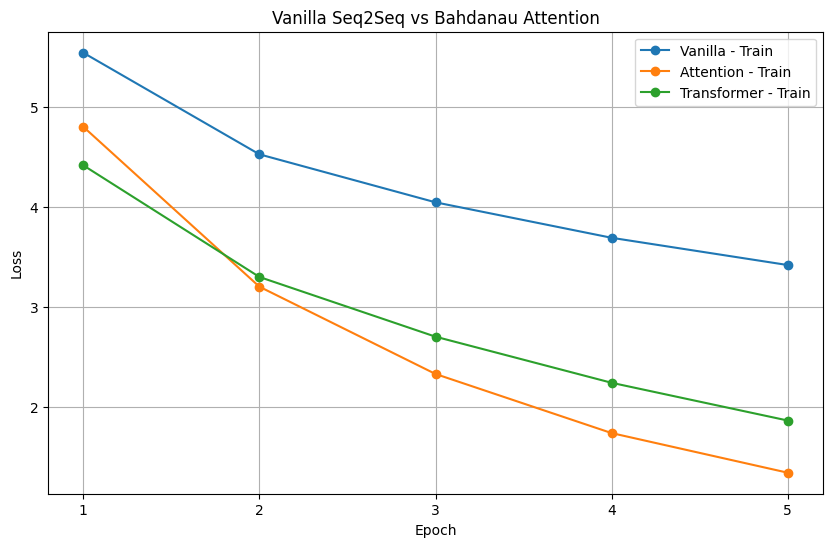

In [ ]:
import matplotlib.pyplot as plt

# Vanilla Seq2Seq
loss_train_vanilla = [
    5.538,
    4.524,
    4.045,
    3.691,
    3.419
]

loss_val_vanilla = [
    5.243,
    4.909,
    4.738,
    4.638,
    4.559
]

# GRU + Bahdanau Attention
loss_train_att = [
    4.799361021518707,
    3.2030399584770204,
    2.3319017128944397,
    1.7419939544208989,
    1.3465553880487442
]

loss_val_att = [
    4.34854558563245,
    3.8652354259490966,
    3.7660784397125244,
    3.729819778012889,
    3.8205104007720947
]
loss_train_transformer = [4.414538484096527,
    3.3000232439041137,
    2.7040608472824097,
    2.2439384257793424,
    1.8672260043621063]

loss_val_transformer = [3.7044644470214845,
    3.2269804153442383,
    2.9366209354400636,
    2.77073268699646,
    2.6793517513275145]

epochs = range(1, 6)

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    loss_train_vanilla,
    marker="o",
    label="Vanilla - Train"
)



plt.plot(
    epochs,
    loss_train_att,
    marker="o",
    label="Attention - Train"
)
plt.plot(
    epochs,
    loss_train_transformer ,
    marker="o",
    label="Transformer - Train"
)



plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Vanilla Seq2Seq vs Bahdanau Attention")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)

plt.show()

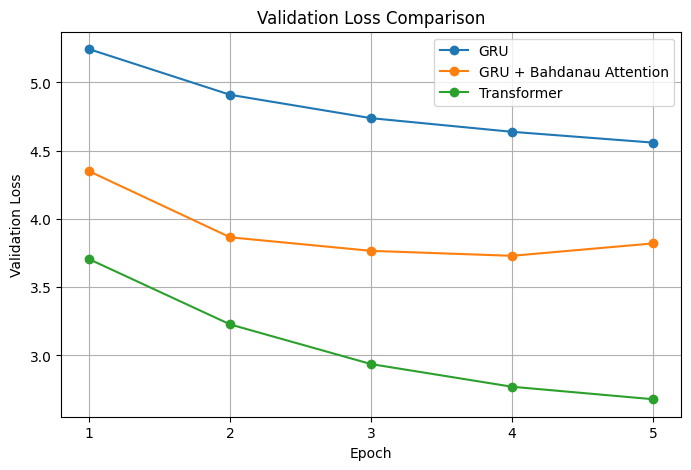

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    loss_val_vanilla,
    marker="o",
    label="GRU"
)

plt.plot(
    epochs,
    loss_val_att,
    marker="o",
    label="GRU + Bahdanau Attention"
)
plt.plot(
    epochs,
    loss_val_transformer,
    marker="o",
    label="Transformer"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Comparison")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
vanilla_final = loss_val_vanilla[-1]
attention_final = loss_val_att[-1]

improvement = (
    (vanilla_final - attention_final)
    / vanilla_final
) * 100

print(f"Vanilla validation loss: {vanilla_final:.3f}")
print(f"Attention validation loss: {attention_final:.3f}")
print(f"Improvement: {improvement:.2f}%")

Vanilla validation loss: 4.559
Attention validation loss: 3.821
Improvement: 16.20%


In [ ]:
import pandas as pd

comparison = pd.DataFrame({
    "Epoch": [1, 2, 3, 4, 5],

    "Vanilla Train Loss": loss_train_vanilla,
    "Vanilla Val Loss": loss_val_vanilla,

    "Attention Train Loss": loss_train_att,
    "Attention Val Loss": loss_val_att,

    "Transformer train loss": loss_train_transformer,
    "Transformer val loss": loss_val_transformer
})

comparison

,Epoch,Vanilla Train Loss,Vanilla Val Loss,Attention Train Loss,Attention Val Loss,Transformer train loss,Transformer val loss
0,1,5.538,5.243,4.799361,4.348546,4.414538,3.704464
1,2,4.524,4.909,3.203040,3.865235,3.300023,3.226980
2,3,4.045,4.738,2.331902,3.766078,2.704061,2.936621
3,4,3.691,4.638,1.741994,3.729820,2.243938,2.770733
4,5,3.419,4.559,1.346555,3.820510,1.867226,2.679352
